In [ ]:
# Shared analysis modules (cca.py, emg32_cca.py, ...) live in ../src
import sys
from pathlib import Path
_src = next((p / 'src' for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'cca.py').is_file()),
            Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis\src'))
sys.path.insert(0, str(_src))

# SSVEP spectral and direct CCA-score analysis

This notebook analyses blocks 2–4 of the paddle and leaf games; block 1 is excluded. **Power spectra are shown first**, using a Chronux-style DPSS multitaper spectrum with `tapers = [1, 1]` (time-bandwidth product 1, one taper). The later plots are raw `score_17` and `score_19` values recomputed from EEG—not the game's `NF17`, `NF19`, or signed NF logs.

CCA reproduces the math in `RT_acquisition_CCA.m`: a 1 s causal window, `round(fs/50)` delayed subtraction, common-average reference, one sine/cosine harmonic, covariance regularizers `1e-6`/`1e-8`, and eight power iterations. As in MATLAB, referencing precedes channel selection: the 16 non-saturated recorded channels form the reference and mapped posterior channels `raw9`–`raw16` are scored. The recording rate is 250 Hz rather than 128 Hz.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd
from scipy import signal

from cca import rolling_cca_scores

ROOT = Path.cwd()
if not (ROOT / 'cca.py').exists():
    ROOT = Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT = ROOT / 'data/2026-10-06'
# Block 1 is intentionally excluded for both games.
PADDLE_FILES = [DATA_ROOT / stamp / f'{stamp}_raw.csv' for stamp in (
    'eeg_20261006_153213', 'eeg_20261006_155629')]
LEAF_FILES = [DATA_ROOT / stamp / f'{stamp}_raw.csv' for stamp in (
    'eeg_20261006_160348', 'eeg_20261006_161145')]
REFERENCE_COLUMNS = [f'raw{i}' for i in range(1, 17)]
CHANNELS = {'raw9': 'Cz', 'raw10': 'Pz', 'raw11': 'P4', 'raw12': 'T6',
            'raw13': 'T5', 'raw14': 'P3', 'raw15': 'O2', 'raw16': 'O1'}
FS = 250.0
FREQUENCIES = (17.0, 19.0)
MICROVOLTS_PER_COUNT = 4.5 / 24 / (2**23 - 1) * 1e6
MAINS_HZ, BANDPASS_HZ, MAX_PTP_UV = 50.0, (5.0, 45.0), 250.0
# Change this one value to use a different trial-start-locked power epoch.
POWER_EPOCH_SECONDS = 2.0
SNR_GUARD_HZ, SNR_NOISE_HZ = 0.5, 2.0
END_LOCKED_SECONDS, SUCCESS_LOCKED_SECONDS = 4.0, 3.0
CCA_STEP_SECONDS = 0.1
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 10})

In [2]:
def first_marker_rows(markers, value):
    """Return only the first CSV row of every consecutive run of a trigger."""
    hit = markers == value
    return np.flatnonzero(hit & np.r_[True, ~hit[:-1]])

def pair_bounds(starts, stops):
    pairs, j = [], 0
    for start in starts:
        while j < len(stops) and stops[j] <= start:
            j += 1
        if j == len(stops):
            break
        pairs.append((int(start), int(stops[j])))
        j += 1
    return pairs

def spectrum_preprocess(raw_counts):
    eeg = signal.detrend(raw_counts * MICROVOLTS_PER_COUNT, axis=0, type='linear')
    b, a = signal.iirnotch(MAINS_HZ, Q=30, fs=FS)
    eeg = signal.sosfiltfilt(signal.tf2sos(b, a), eeg, axis=0)
    sos = signal.butter(4, BANDPASS_HZ, btype='bandpass', fs=FS, output='sos')
    eeg = signal.sosfiltfilt(sos, eeg, axis=0)
    return eeg - eeg.mean(axis=1, keepdims=True)

def load_trials(paths, labels, success_trigger=None):
    trials, diagnostics = [], []
    for block, path in enumerate(paths, 2):
        table = pd.read_csv(path, usecols=['seq', *REFERENCE_COLUMNS, 'marker'])
        raw_all = table[REFERENCE_COLUMNS].to_numpy(float)
        raw = table[list(CHANNELS)].to_numpy(float)
        eeg_uv = spectrum_preprocess(raw)
        markers = table.marker.to_numpy(int)
        sequence = table.seq.to_numpy(np.int64)
        starts = np.sort(np.concatenate([first_marker_rows(markers, code) for code in labels]))
        pairs = pair_bounds(starts, first_marker_rows(markers, 30))
        successes = 0
        for number, (start, stop) in enumerate(pairs, 1):
            ring_samples = int(round(FS)) + int(round(FS / 50.0))
            context_start = max(0, start - ring_samples + 1)
            success_offset = None
            if success_trigger is not None:
                rows = first_marker_rows(markers[start:stop], success_trigger)
                if len(rows):
                    success_offset, successes = int(rows[0]), successes + 1
            trigger = int(markers[start])
            trials.append({'block': block, 'trial': number, 'trigger': trigger,
                'condition': labels[trigger], 'cca_counts': raw_all[context_start:stop],
                'cca_sequence': sequence[context_start:stop],
                'cca_time_offset_seconds': (start - context_start) / FS,
                'eeg_uv': eeg_uv[start:stop], 'sequence': sequence[start:stop],
                'duration_seconds': (stop - start) / FS,
                'success_offset': success_offset})
        diagnostics.append({'block': block, 'file': path.parent.name, 'rows': len(table),
            'trials': len(pairs), 'successes': successes,
            'sequence_gaps': int(np.count_nonzero(np.diff(sequence) != 1))})
    return trials, pd.DataFrame(diagnostics)

paddle_labels = {20: 'Left target', 21: 'Right target'}
leaf_labels = {20: 'C1 / Pointing', 21: 'C2 / Moving'}
paddle_trials, paddle_diagnostics = load_trials(PADDLE_FILES, paddle_labels)
leaf_trials, leaf_diagnostics = load_trials(LEAF_FILES, leaf_labels, 50)

def mark_power_quality(trials):
    """The sole trial-rejection rule: finite data and <=250 µV PTP on every channel."""
    for trial in trials:
        peak_to_peak = np.ptp(trial['eeg_uv'], axis=0)
        trial['max_ptp_uv'] = float(np.max(peak_to_peak))
        trial['power_ok'] = bool(np.isfinite(trial['eeg_uv']).all() and
                                 np.all(peak_to_peak <= MAX_PTP_UV))
        trial['is_success'] = (trial['duration_seconds'] < 10.0)

mark_power_quality(paddle_trials)
mark_power_quality(leaf_trials)
display(pd.concat({'Paddle': paddle_diagnostics, 'Leaf': leaf_diagnostics}, names=['game']))
print('Paddle blocks included:', sorted({t['block'] for t in paddle_trials}))
print('Leaf blocks included:', sorted({t['block'] for t in leaf_trials}))
print('Paddle trials:', len(paddle_trials), '| duration-defined successes:',
      sum(t['is_success'] for t in paddle_trials), '| bad-power trials:',
      sum(not t['power_ok'] for t in paddle_trials))
print('Leaf trials:', len(leaf_trials), '| success-marker trials:',
      sum(t['success_offset'] is not None for t in leaf_trials), '| bad-power trials:',
      sum(not t['power_ok'] for t in leaf_trials))
bad_power_audit = [(t['block'], t['trial'], t['condition'], round(t['max_ptp_uv'], 2))
                   for t in paddle_trials + leaf_trials if not t['power_ok']]
print('Bad-power audit (block, trial, condition, max PTP µV):', bad_power_audit)

block                 file    rows  trials  successes  sequence_gaps
game                                                                          
Paddle 0      2  eeg_20261006_153213  137182      48          0              0
       1      3  eeg_20261006_155629  107491      48          0              0
Leaf   0      2  eeg_20261006_160348  106877      24         14              0
       1      3  eeg_20261006_161145  104675      24         16              0

Paddle blocks included: [2, 3]
Leaf blocks included: [2, 3]
Paddle trials: 96 | duration-defined successes: 92 | bad-power trials: 0
Leaf trials: 48 | success-marker trials: 30 | bad-power trials: 0
Bad-power audit (block, trial, condition, max PTP µV): []


## 1. Power spectra — shown before CCA

For spectral interpretability only, counts are converted to µV, linearly detrended, 50 Hz-notched, 5–45 Hz zero-phase filtered, and common-average referenced. As in `analysisSSVEPcsvBi.py`, each condition shows **average/induced power**, **local spectral SNR**, and **evoked power**. Every spectrum uses the first `POWER_EPOCH_SECONDS` after trial start (currently 2 s) with DPSS `NW=1, K=1` (`tapers=[1,1]`). **No zero-padding, frequency interpolation, convolution, or spectral smoothing is applied:** line vertices are the actual Fourier bins, joined only for visual readability. The third row pools all eligible trials in that game. An additional **3×3 comparison figure** has columns for the two conditions and all trials, with rows for conventional PSD, the same hardware-friendly CCA score recomputed at every frequency, and CCA-weighted power. For CCA-weighted power, linear PSD is multiplied by the corresponding raw CCA score within each trial and frequency, products are averaged across trials, and the result is converted to dB only for display. Bad-power trials are rejected globally; a trial shorter than the configured epoch remains in CCA analyses but cannot contribute to a fixed-length power spectrum.

In [3]:
def mtspectrum_11(data):
    """Chronux-style tapers=[1,1] spectrum at raw, unpadded Fourier bins."""
    taper = signal.windows.dpss(len(data), NW=1.0, Kmax=1, sym=False)[0]
    return signal.periodogram(data, fs=FS, window=taper, nfft=len(data),
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def spectral_snr_db(power, frequencies):
    frequency_step = frequencies[1] - frequencies[0]
    guard_bins = max(1, int(round(SNR_GUARD_HZ / frequency_step)))
    noise_bins = max(guard_bins + 1, int(round(SNR_NOISE_HZ / frequency_step)))
    snr = np.full_like(power, np.nan, dtype=float)
    for index in range(noise_bins, len(power) - noise_bins):
        left = power[index-noise_bins:index-guard_bins]
        right = power[index+guard_bins+1:index+noise_bins+1]
        local_noise = np.concatenate((left, right), axis=0).mean(axis=0)
        snr[index] = 10*np.log10(np.maximum(power[index], np.finfo(float).tiny) /
                                  np.maximum(local_noise, np.finfo(float).tiny))
    return snr

def condition_spectra(trials, condition=None):
    all_condition = list(trials) if condition is None else [
        t for t in trials if t['condition'] == condition]
    clean = [t for t in all_condition if t['power_ok']]
    epoch_samples = int(round(POWER_EPOCH_SECONDS * FS))
    eligible = [t for t in clean if len(t['eeg_uv']) >= epoch_samples]
    if not eligible:
        raise ValueError(f'No trials are long enough for a {POWER_EPOCH_SECONDS:g} s epoch')
    start_locked_epochs = np.stack([t['eeg_uv'][:epoch_samples] for t in eligible])
    trial_power = [mtspectrum_11(epoch)[1] for epoch in start_locked_epochs]
    frequencies, _ = mtspectrum_11(start_locked_epochs[0])
    average_power = np.mean(trial_power, axis=0)
    evoked_waveform = start_locked_epochs.mean(axis=0)
    _, evoked_power = mtspectrum_11(evoked_waveform)
    return (frequencies, average_power, spectral_snr_db(average_power, frequencies),
            evoked_power, len(eligible), len(all_condition) - len(clean),
            len(clean) - len(eligible))

def trial_cca_score_spectrum(trial, frequencies):
    """Average exact acquisition-like CCA scores over the start-locked epoch."""
    ring = int(round(FS)) + int(round(FS / 50.0))
    step = int(round(CCA_STEP_SECONDS * FS))
    context_samples = int(round(trial['cca_time_offset_seconds'] * FS))
    analysis_stop = context_samples + int(round(POWER_EPOCH_SECONDS * FS))
    cca_data = trial['cca_counts'][:analysis_stop]
    cca_sequence = trial['cca_sequence'][:analysis_stop]
    times, scores = rolling_cca_scores(
        cca_data, FS, frequencies, step_seconds=CCA_STEP_SECONDS,
        n_harmonics=1, n_power_iterations=8, demean_rereference=True,
        z_score=False, score_channel_indices=np.arange(8, 16))
    times -= trial['cca_time_offset_seconds']
    valid = (times >= 0) & (times <= POWER_EPOCH_SECONDS)
    stops = np.arange(ring, len(cca_sequence) + 1, step)
    for row, stop in enumerate(stops):
        if np.any(np.diff(cca_sequence[stop-ring:stop]) != 1):
            valid[row] = False
    if not np.any(valid):
        return np.full(len(frequencies), np.nan)
    return np.mean(scores[valid], axis=0)

def plot_spectrum_comparison_grid(trials, conditions, title, target_names):
    epoch_samples = int(round(POWER_EPOCH_SECONDS * FS))
    frequencies = np.fft.rfftfreq(epoch_samples, d=1/FS)
    frequencies = frequencies[(frequencies >= 5) & (frequencies <= 30)]
    eligible = [t for t in trials if t['power_ok'] and len(t['eeg_uv']) >= epoch_samples]
    spectra = np.stack([trial_cca_score_spectrum(t, frequencies) for t in eligible])
    trial_power = []
    for trial in eligible:
        power_frequencies, power = mtspectrum_11(trial['eeg_uv'][:epoch_samples])
        power_mask = (power_frequencies >= 5) & (power_frequencies <= 30)
        if not np.allclose(power_frequencies[power_mask], frequencies):
            raise RuntimeError('Power and CCA frequency bins do not match')
        trial_power.append(power[power_mask])
    trial_power = np.stack(trial_power)
    plot_conditions = [*conditions, None]
    fig, axes = plt.subplots(3, 3, figsize=(19, 12), sharex=True, sharey='row',
                             constrained_layout=True)
    for column, condition in enumerate(plot_conditions):
        condition_title = 'All trials' if condition is None else condition
        select = np.ones(len(eligible), dtype=bool) if condition is None else np.array(
            [t['condition'] == condition for t in eligible])
        n_selected = np.count_nonzero(select)

        # Row 1: conventional induced PSD, averaged in linear units.
        mean_power = np.nanmean(trial_power[select], axis=0)
        power_db = 10*np.log10(np.maximum(mean_power, np.finfo(float).tiny))
        for channel_index, channel_label in enumerate(CHANNELS.values()):
            axes[0, column].plot(frequencies, power_db[:, channel_index],
                                 lw=.8, alpha=.42, label=channel_label)
        axes[0, column].plot(frequencies, np.nanmean(power_db, axis=1),
                             color='black', lw=2.2, label='Channel mean', zorder=4)

        # Row 2: the hardware-friendly CCA score at each frequency.
        values = spectra[select]
        mean = np.nanmean(values, axis=0)
        sem = np.nanstd(values, axis=0, ddof=1) / np.sqrt(
            np.sum(np.isfinite(values), axis=0))
        axes[1, column].plot(frequencies, mean, color='black', lw=2.0,
                             marker='.', ms=4, label='Across-trial mean')
        axes[1, column].fill_between(frequencies, mean-sem, mean+sem,
                                    color='black', alpha=.14, label='SEM')

        # Row 3: multiply linear PSD by matching CCA score before averaging.
        weighted = trial_power[select] * spectra[select, :, None]
        mean_weighted = np.nanmean(weighted, axis=0)
        weighted_db = 10*np.log10(np.maximum(mean_weighted, np.finfo(float).tiny))
        for channel_index, channel_label in enumerate(CHANNELS.values()):
            axes[2, column].plot(frequencies, weighted_db[:, channel_index],
                                 lw=.8, alpha=.42, label=channel_label)
        axes[2, column].plot(frequencies, np.nanmean(weighted_db, axis=1),
                             color='black', lw=2.2, label='Channel mean', zorder=4)

        row_names = ('Conventional PSD', 'CCA score spectrum', 'CCA-weighted PSD')
        for row, row_name in enumerate(row_names):
            ax = axes[row, column]
            for frequency, label in target_names.items():
                ax.axvline(frequency,
                           color={17: '#0072B2', 19: '#D55E00'}[frequency],
                           ls='--', lw=1.4, label=label)
            ax.set(title=f'{condition_title}: {row_name} (n = {n_selected})',
                   xlim=(5, 30))
            ax.xaxis.set_major_locator(MultipleLocator(2))
        axes[1, column].set_ylim(bottom=0)
        axes[2, column].set_xlabel('Frequency (Hz)')

    axes[0, 0].set_ylabel(r'PSD (dB $\mu V^2$/Hz)')
    axes[1, 0].set_ylabel('Hardware-friendly CCA score')
    axes[2, 0].set_ylabel(r'CCA-weighted PSD (dB $\mu V^2$/Hz)')
    axes[0, -1].legend(frameon=False, fontsize=8, ncol=2)
    axes[1, -1].legend(frameon=False, fontsize=8)
    fig.suptitle(
        f'{title}: conventional, CCA, and CCA-weighted spectra (no smoothing)',
        fontsize=13)
    plt.show()

def plot_game_spectra(trials, conditions, title, target_names):
    plot_conditions = [*conditions, None]
    fig, axes = plt.subplots(3, 3, figsize=(19, 12), sharex=True,
                             constrained_layout=True)
    metric_titles = ('Average / induced power', 'Local spectral SNR',
                     f'Evoked power (first {POWER_EPOCH_SECONDS:g} s, start locked)')
    ylabels = (r'PSD (dB $\mu V^2$/Hz)', 'Spectral SNR (dB)',
               r'PSD (dB $\mu V^2$/Hz)')
    for row, condition in enumerate(plot_conditions):
        condition_title = 'All trials' if condition is None else condition
        f, average_power, snr, evoked_power, kept, rejected, too_short = condition_spectra(
            trials, condition)
        displays = (10*np.log10(np.maximum(average_power, np.finfo(float).tiny)),
                    snr, 10*np.log10(np.maximum(evoked_power, np.finfo(float).tiny)))
        mask = (f >= 5) & (f <= 30)
        for column, (display_values, metric_title, ylabel) in enumerate(
                zip(displays, metric_titles, ylabels)):
            ax = axes[row, column]
            for channel_index, channel_label in enumerate(CHANNELS.values()):
                ax.plot(f[mask], display_values[mask, channel_index],
                        lw=.8, alpha=.42, label=channel_label)
            ax.plot(f[mask], np.nanmean(display_values[mask], axis=1),
                    color='black', lw=2.2, label='Channel mean', zorder=4)
            for frequency, label in target_names.items():
                ax.axvline(frequency, color={17: '#0072B2', 19: '#D55E00'}[frequency],
                           ls='--', lw=1.4, label=label)
            ax.set(title=(f'{condition_title}: {metric_title}\n{kept} spectra; '
                          f'{rejected} bad-power / {too_short} shorter than epoch'),
                   ylabel=ylabel, xlim=(5, 30))
            ax.xaxis.set_major_locator(MultipleLocator(2))
    for ax in axes[-1]:
        ax.set_xlabel('Frequency (Hz)')
    axes[0, 0].legend(frameon=False, fontsize=8, ncol=2)
    fig.suptitle(f'{title}: raw Fourier bins, no smoothing (tapers = [1, 1])', fontsize=13)
    plt.show()
    plot_spectrum_comparison_grid(trials, conditions, title, target_names)

paddle_frequency_names = {17: '17 Hz — left grating', 19: '19 Hz — right grating'}
leaf_frequency_names = {17: '17 Hz — C1 / Pointing', 19: '19 Hz — C2 / Moving'}

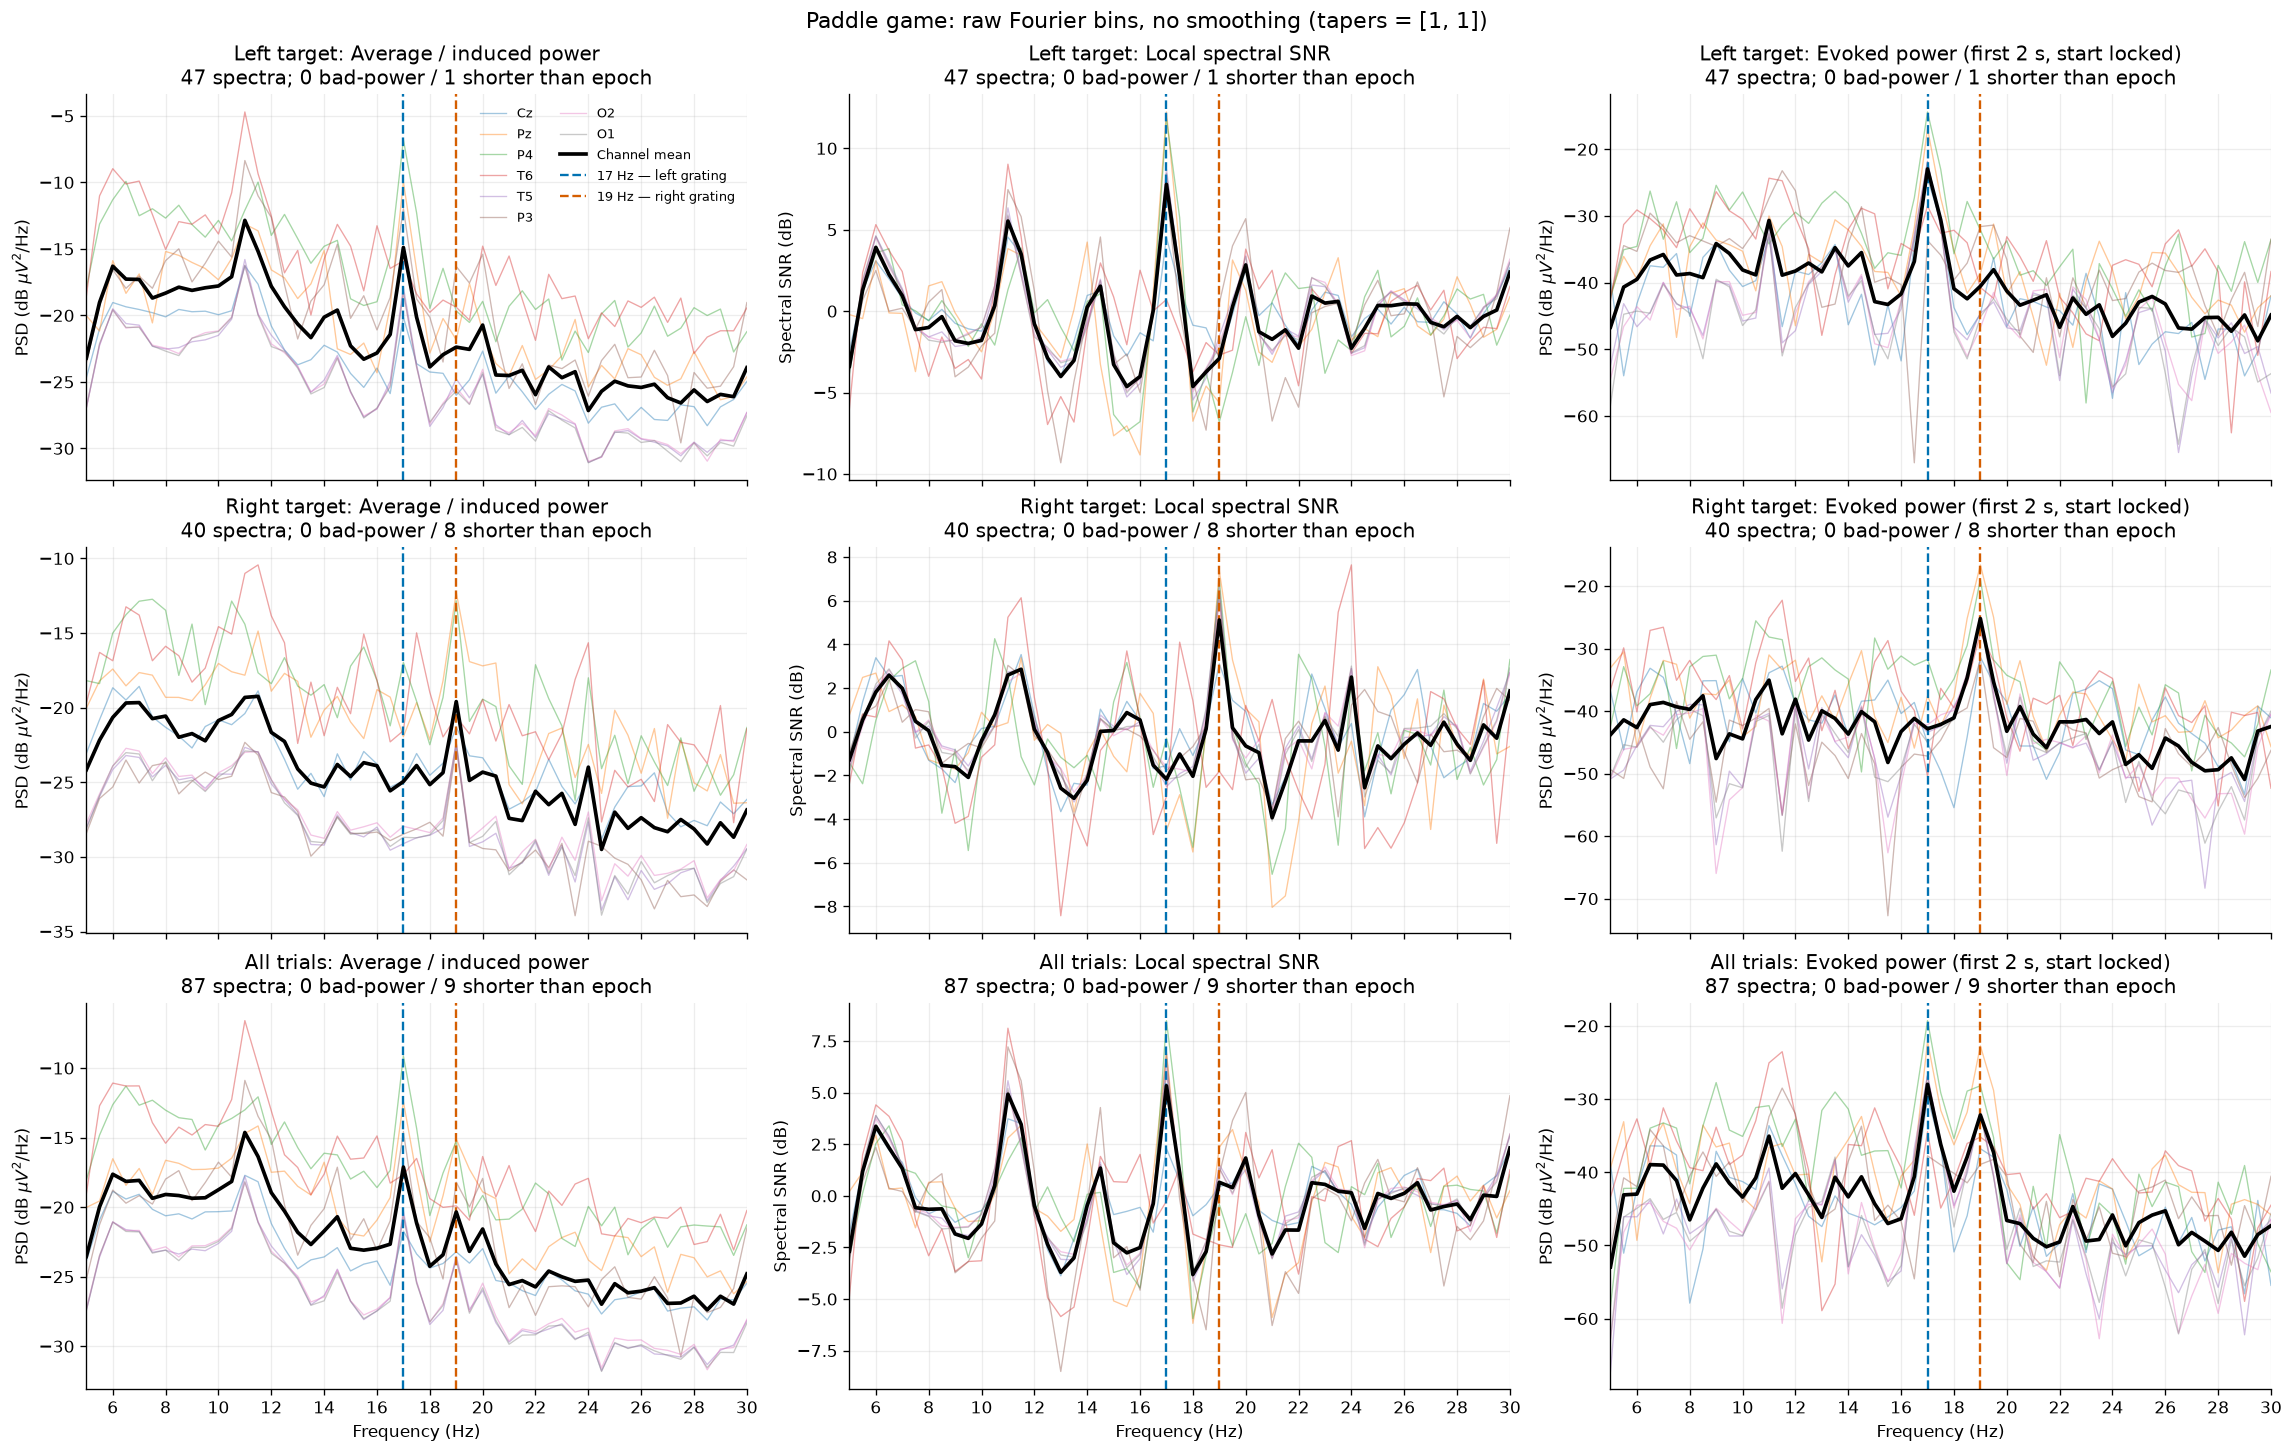

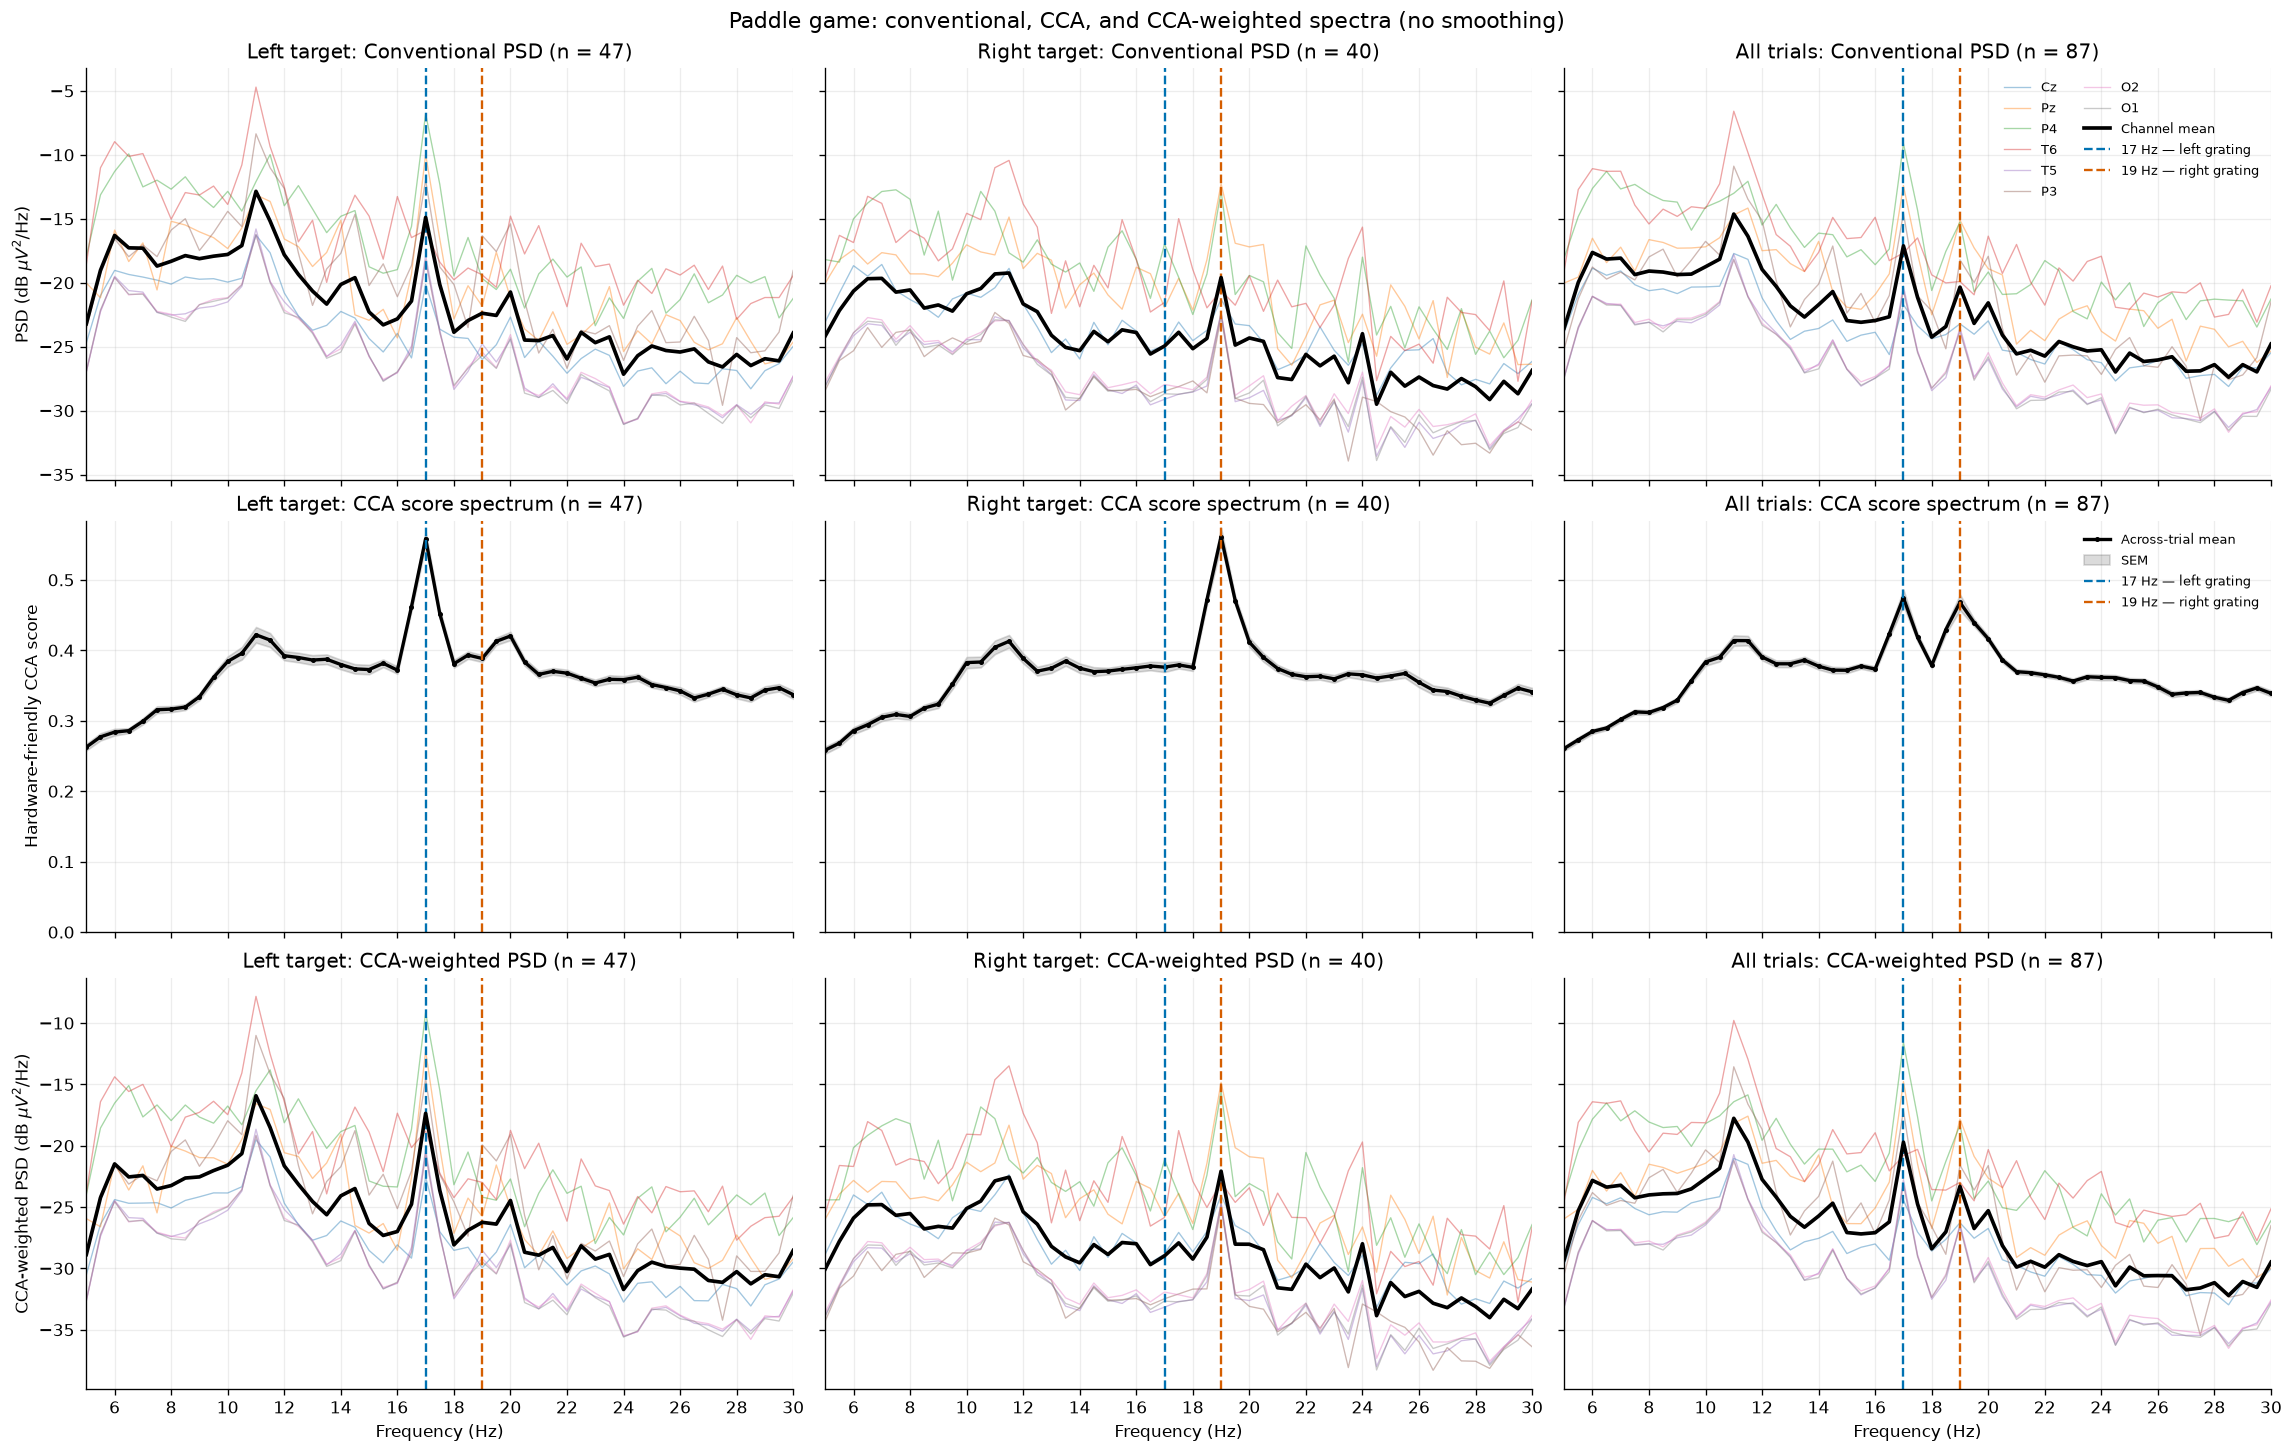

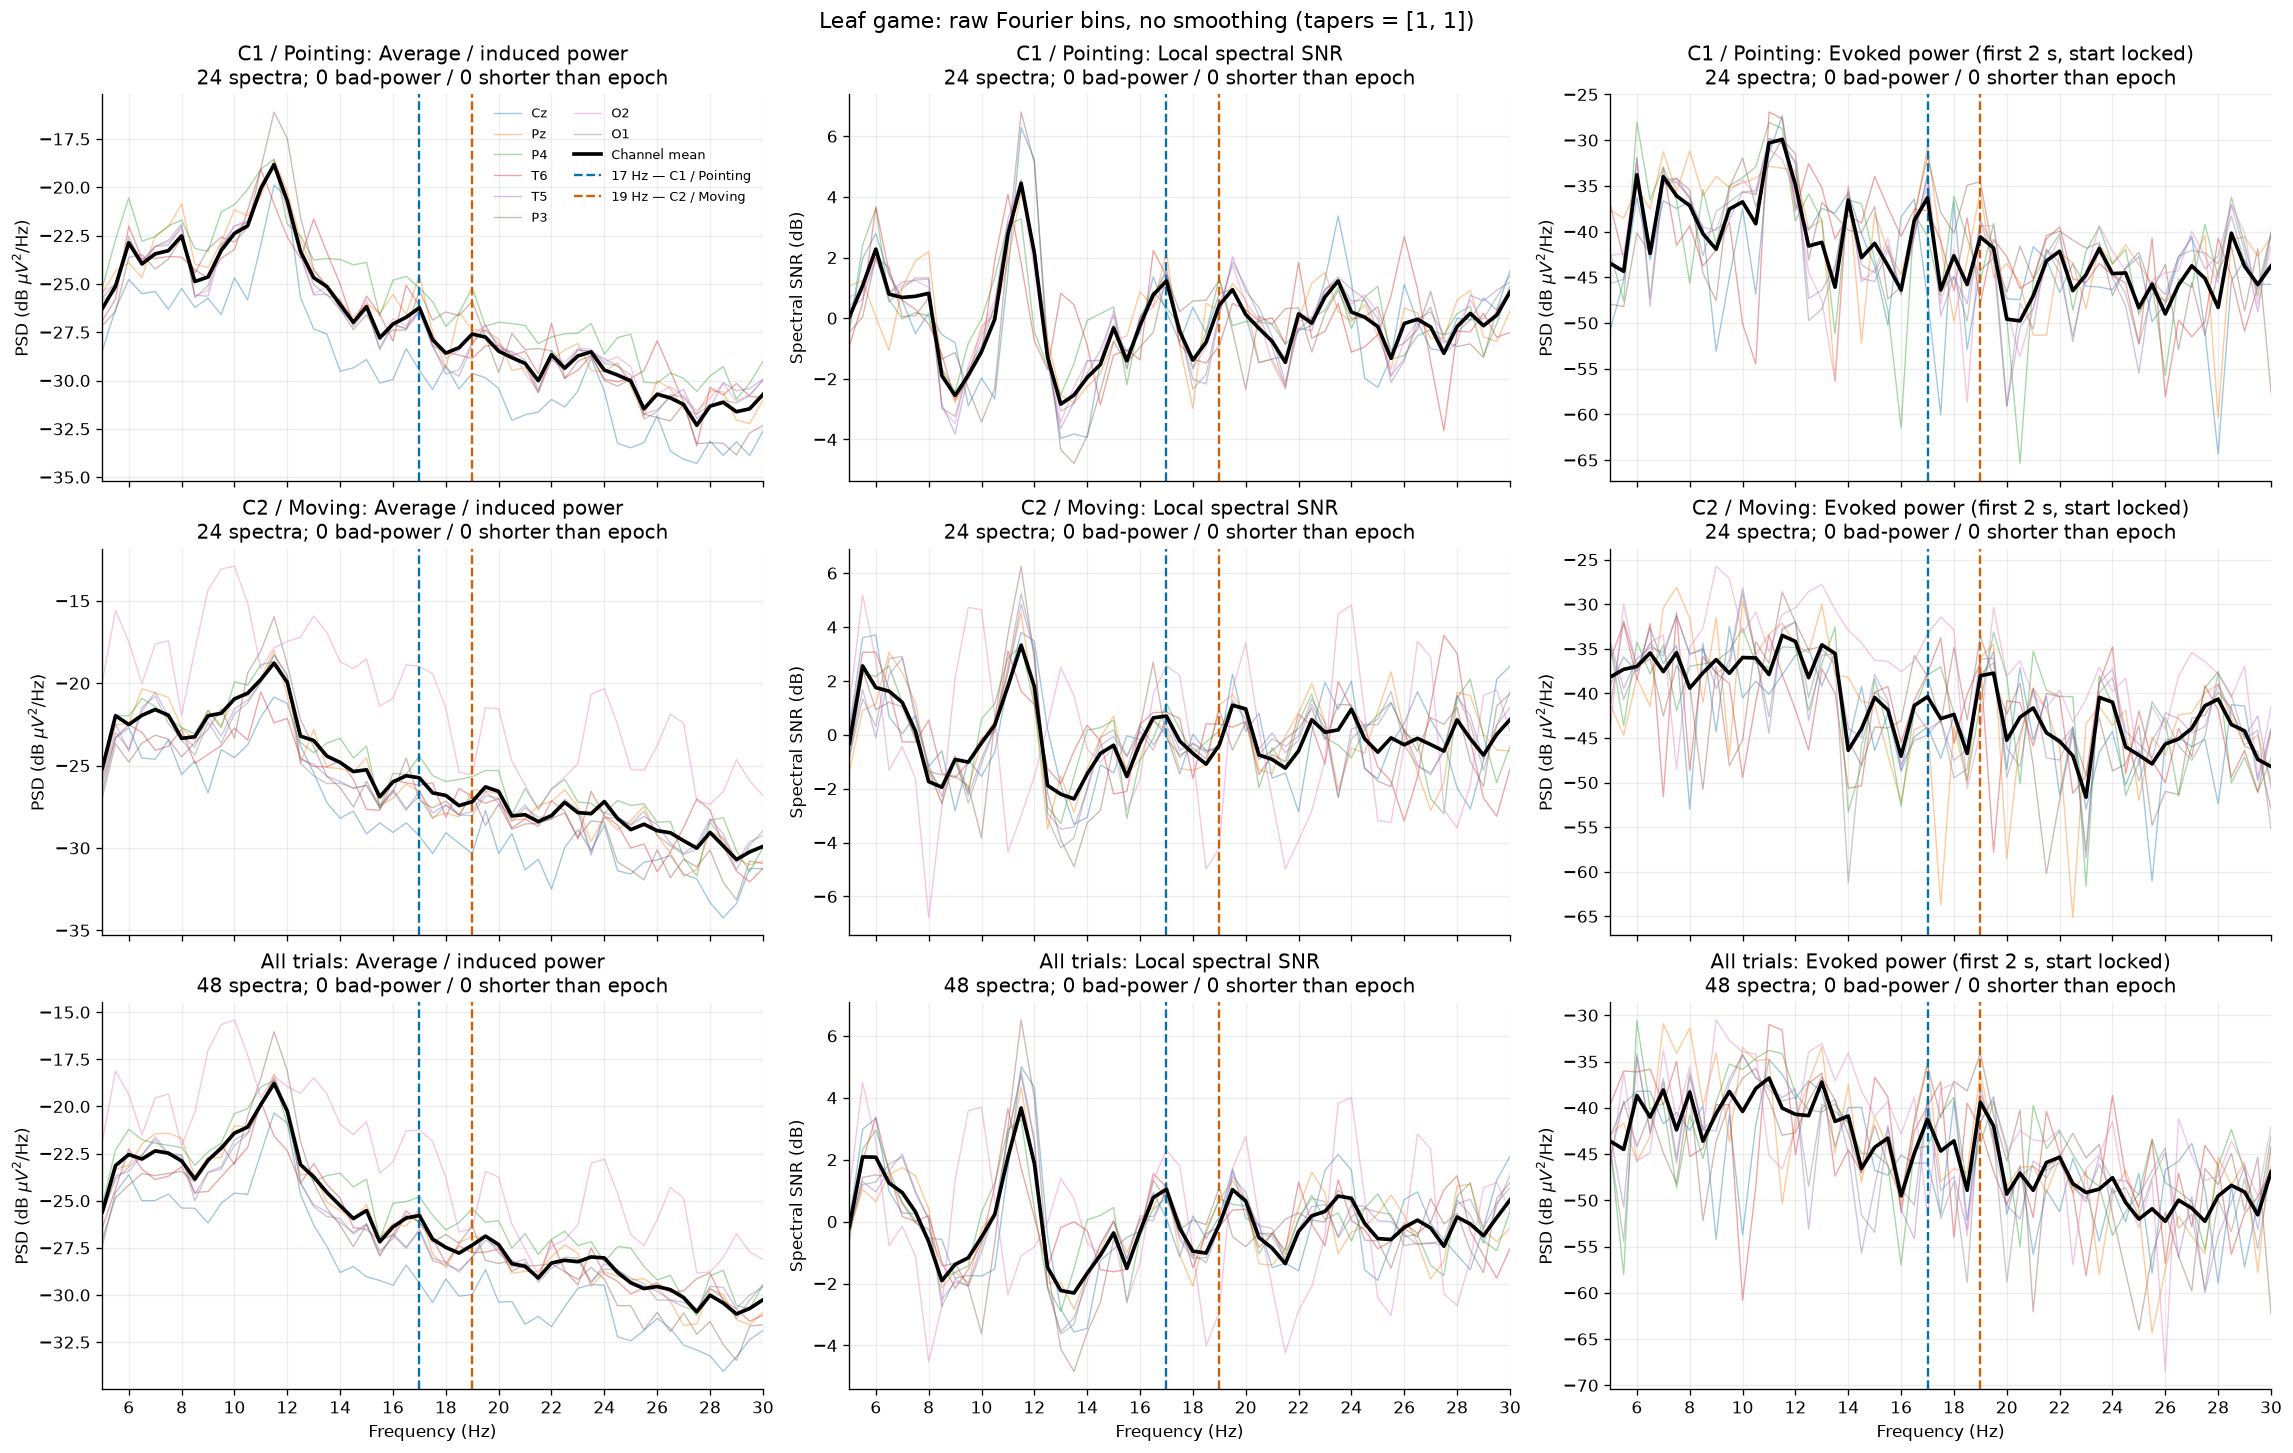

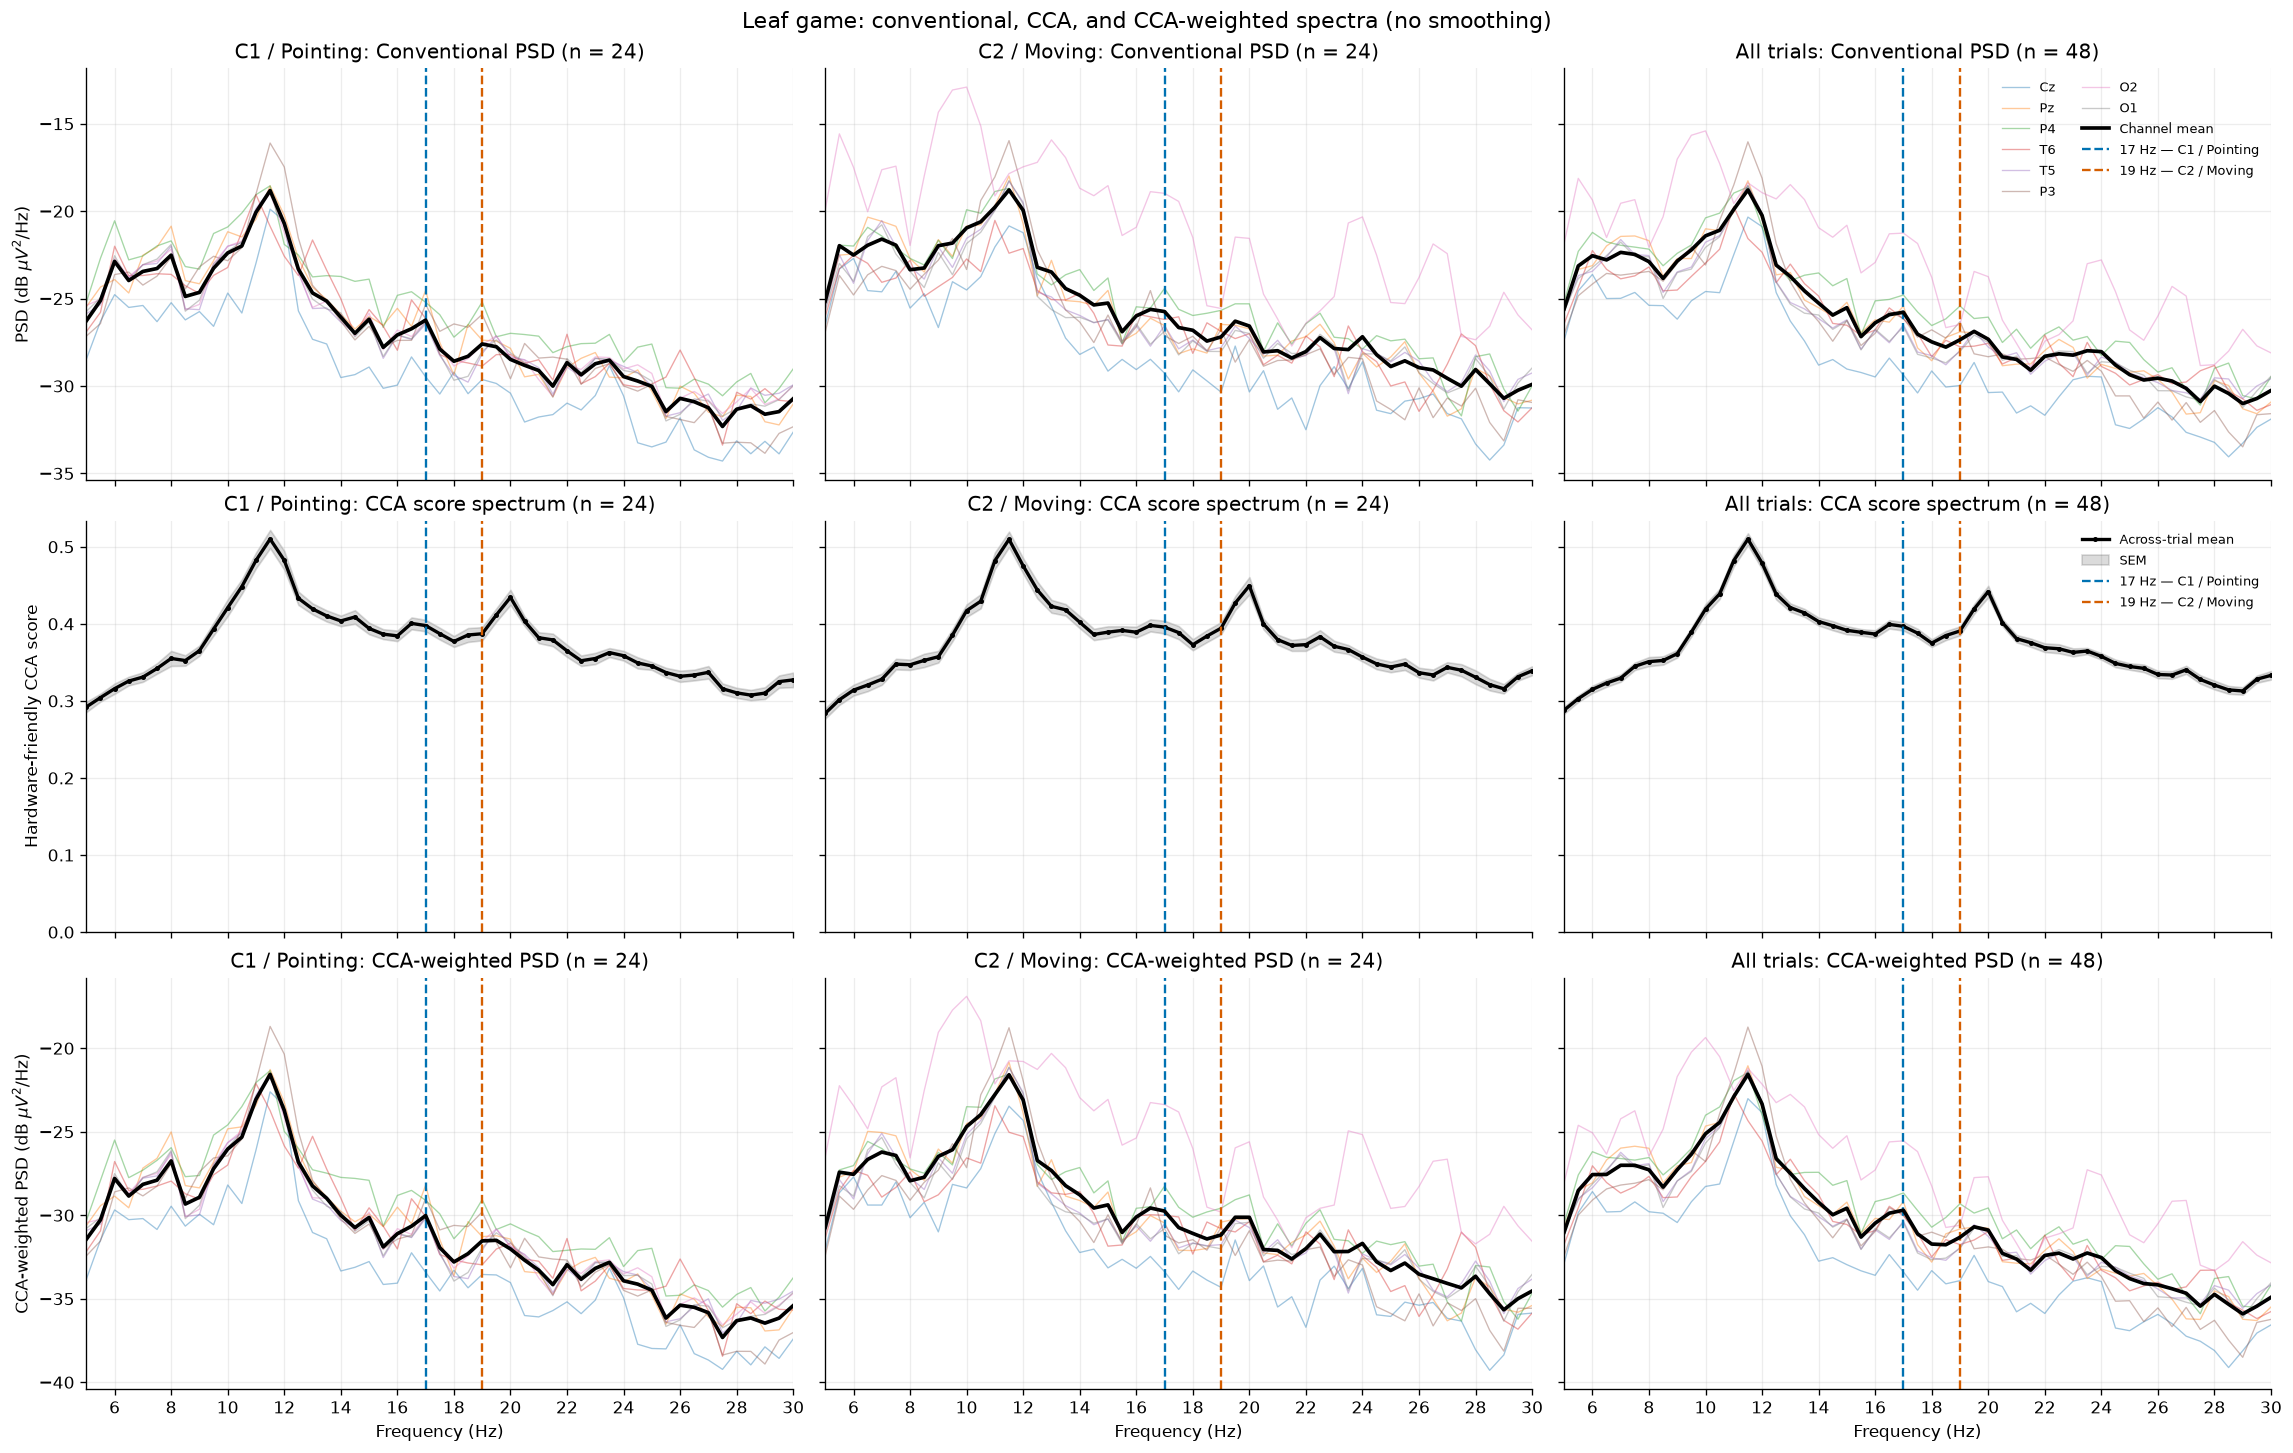

In [4]:
# Intentionally the first result figures.
plot_game_spectra(paddle_trials, list(paddle_labels.values()), 'Paddle game', paddle_frequency_names)
plot_game_spectra(leaf_trials, list(leaf_labels.values()), 'Leaf game', leaf_frequency_names)

## 2. Direct EEG-derived CCA scores

Nothing below reads the game's NF trace columns. Each point is a newly computed raw hardware-friendly CCA score from the EEG. Times refer to the end of the causal 1 s CCA window. To mirror the live MATLAB ring buffer and retain even sub-1.02 s trials, initial points use the available pre-trial ring context. Shading is across-trial SEM; solid lines are across-trial means. The common bad-power mask above is the only trial-quality rejection; success-only panels are intentional condition subsets rather than artifact rejection.

In [5]:
def add_direct_cca(trials):
    ring = int(round(FS)) + int(round(FS / 50))
    step = int(round(CCA_STEP_SECONDS * FS))
    rejected = 0
    for trial in trials:
        times, scores = rolling_cca_scores(trial['cca_counts'], FS, FREQUENCIES,
            step_seconds=CCA_STEP_SECONDS, n_harmonics=1, n_power_iterations=8,
            demean_rereference=True, z_score=False, score_channel_indices=np.arange(8, 16))
        stops = np.arange(ring, len(trial['cca_sequence']) + 1, step)
        for row, stop in enumerate(stops):
            if np.any(np.diff(trial['cca_sequence'][stop-ring:stop]) != 1):
                scores[row], rejected = np.nan, rejected + 1
        trial['cca_time'] = times - trial['cca_time_offset_seconds']
        trial['cca_scores'] = scores
    return rejected

def aggregate_scores(trials, condition, grid, lock='start', success_rule=None):
    # Every power-clean trial is retained unless this is explicitly a success-only view.
    chosen = [t for t in trials if t['condition'] == condition and t['power_ok']]
    if success_rule == 'duration':
        chosen = [t for t in chosen if t['is_success']]
    elif success_rule == 'marker':
        chosen = [t for t in chosen if t['success_offset'] is not None]
    result = []
    for trial in chosen:
        times = trial['cca_time'].copy()
        if lock == 'success':
            times -= trial['success_offset'] / FS
        elif lock == 'end':
            times -= trial['duration_seconds']
        values = np.full((len(grid), len(FREQUENCIES)), np.nan)
        for i in range(len(FREQUENCIES)):
            valid = np.isfinite(trial['cca_scores'][:, i])
            if valid.sum() >= 2:
                valid_times = times[valid]
                candidate = np.interp(grid, valid_times, trial['cca_scores'][valid, i],
                                      left=np.nan, right=np.nan)
                # Do not interpolate across a score rejected for a sequence gap.
                supported = np.min(np.abs(grid[:, None] - valid_times[None, :]), axis=1) <= 0.51 * CCA_STEP_SECONDS
                values[supported, i] = candidate[supported]
        result.append(values)
    return np.stack(result), len(chosen)

def mean_sem(values):
    count = np.isfinite(values).sum(axis=0)
    total = np.nansum(values, axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    ss = np.nansum((values - mean) ** 2, axis=0)
    variance = np.divide(ss, count - 1, out=np.full_like(total, np.nan), where=count > 1)
    return mean, np.sqrt(variance) / np.sqrt(np.maximum(count, 1))

def plot_cca(trials, conditions, grid, title, frequency_names, lock='start', success_rule=None):
    colors = ('#0072B2', '#D55E00')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True,
                             constrained_layout=True)
    for ax, condition in zip(axes, conditions):
        values, n = aggregate_scores(trials, condition, grid, lock, success_rule)
        mean, sem = mean_sem(values)
        for i, (frequency, name) in enumerate(zip(FREQUENCIES, frequency_names)):
            ax.plot(grid, mean[:, i], color=colors[i], lw=2.2, label=f'{frequency:g} Hz — {name}')
            ax.fill_between(grid, mean[:, i]-sem[:, i], mean[:, i]+sem[:, i],
                            color=colors[i], alpha=.18)
        if lock in ('success', 'end'):
            event_label = 'Success marker 50' if lock == 'success' else 'Trial end'
            ax.axvline(0, color='black', ls=':', lw=1.3, label=event_label)
        xlabel = {'start': 'Time from trial start (s)',
                  'success': 'Time from success (s)', 'end': 'Time from trial end (s)'}[lock]
        ax.set(title=f'{condition} (n = {n} trials)',
               xlabel=xlabel,
               xlim=(grid[0], grid[-1]), ylim=(0, None))
        ax.legend(frameon=False, fontsize=9)
    axes[0].set_ylabel('Direct hardware-friendly CCA score')
    fig.suptitle(title, fontsize=13)
    plt.show()

print('CCA gap-window rejects — paddle:', add_direct_cca(paddle_trials),
      'leaf:', add_direct_cca(leaf_trials))

CCA gap-window rejects — paddle: 0 leaf: 0


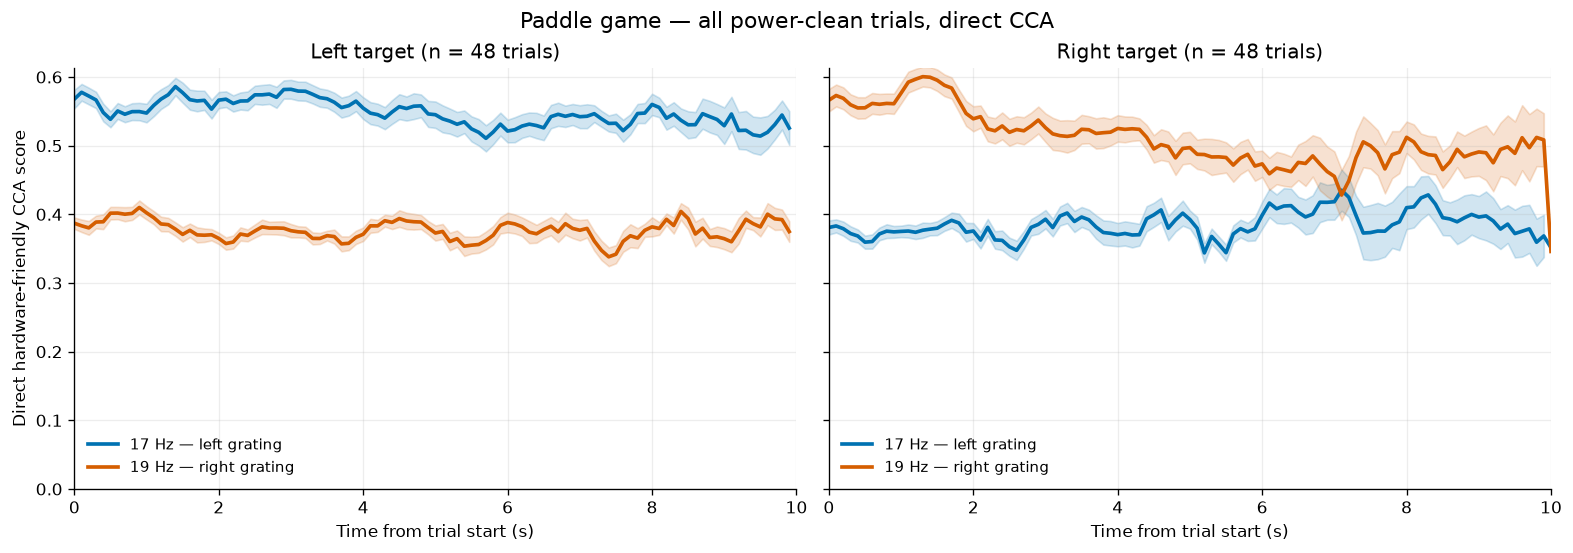

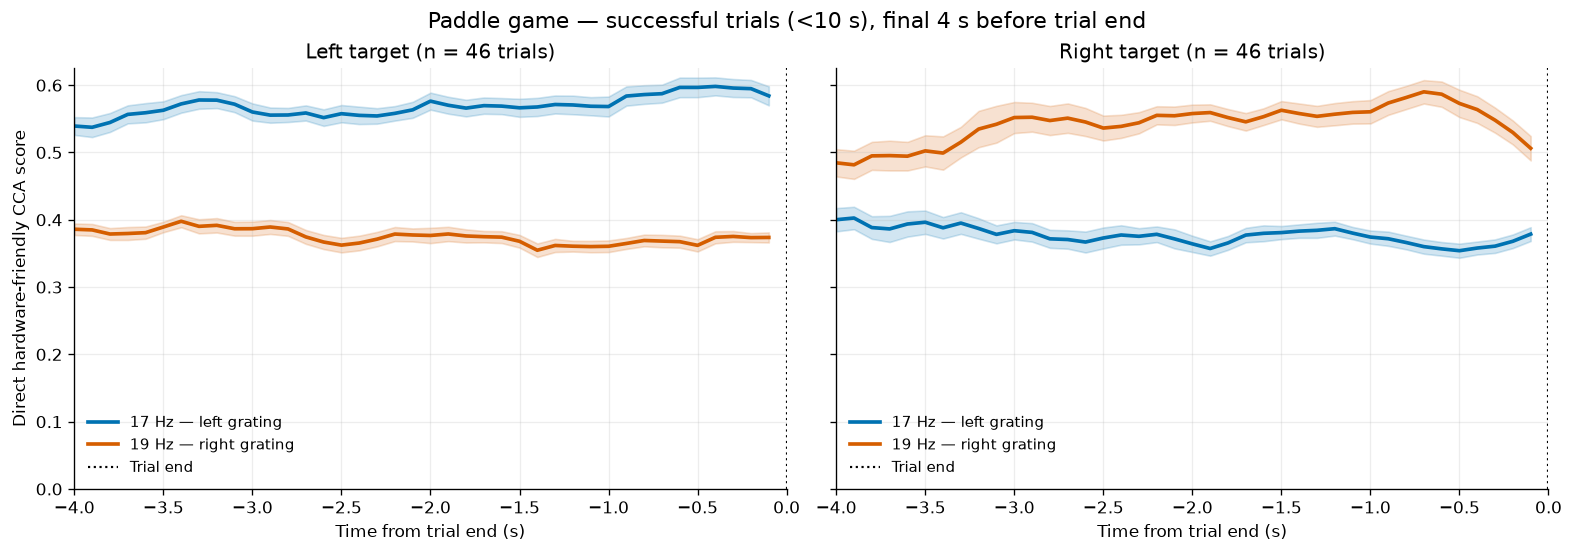

In [6]:
# All power-clean paddle trials: trial-start locked, one plot per target side.
paddle_time = np.arange(0, 10 + CCA_STEP_SECONDS/2, CCA_STEP_SECONDS)
plot_cca(paddle_trials, list(paddle_labels.values()), paddle_time,
         'Paddle game — all power-clean trials, direct CCA',
         ('left grating', 'right grating'), lock='start')

# Success is defined exactly as requested: trial duration strictly below 10 s.
paddle_end_time = np.linspace(-END_LOCKED_SECONDS, 0,
                              int(round(END_LOCKED_SECONDS / CCA_STEP_SECONDS)) + 1)
plot_cca(paddle_trials, list(paddle_labels.values()), paddle_end_time,
         'Paddle game — successful trials (<10 s), final 4 s before trial end',
         ('left grating', 'right grating'), lock='end', success_rule='duration')

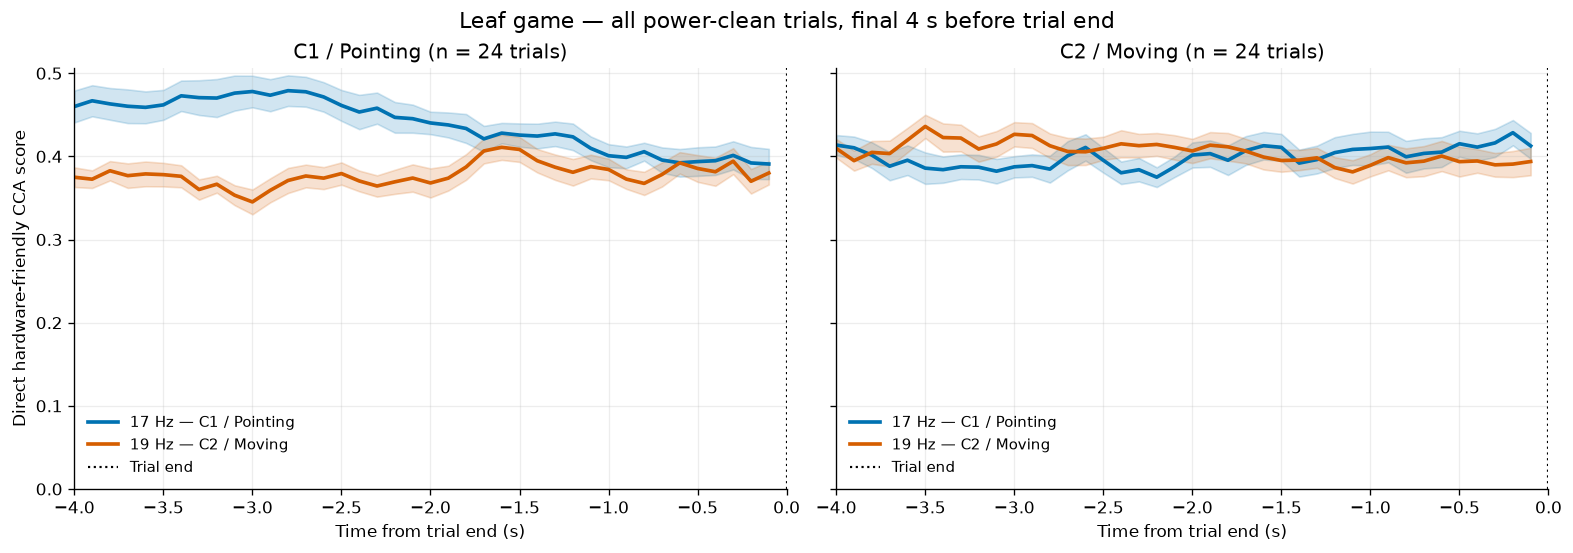

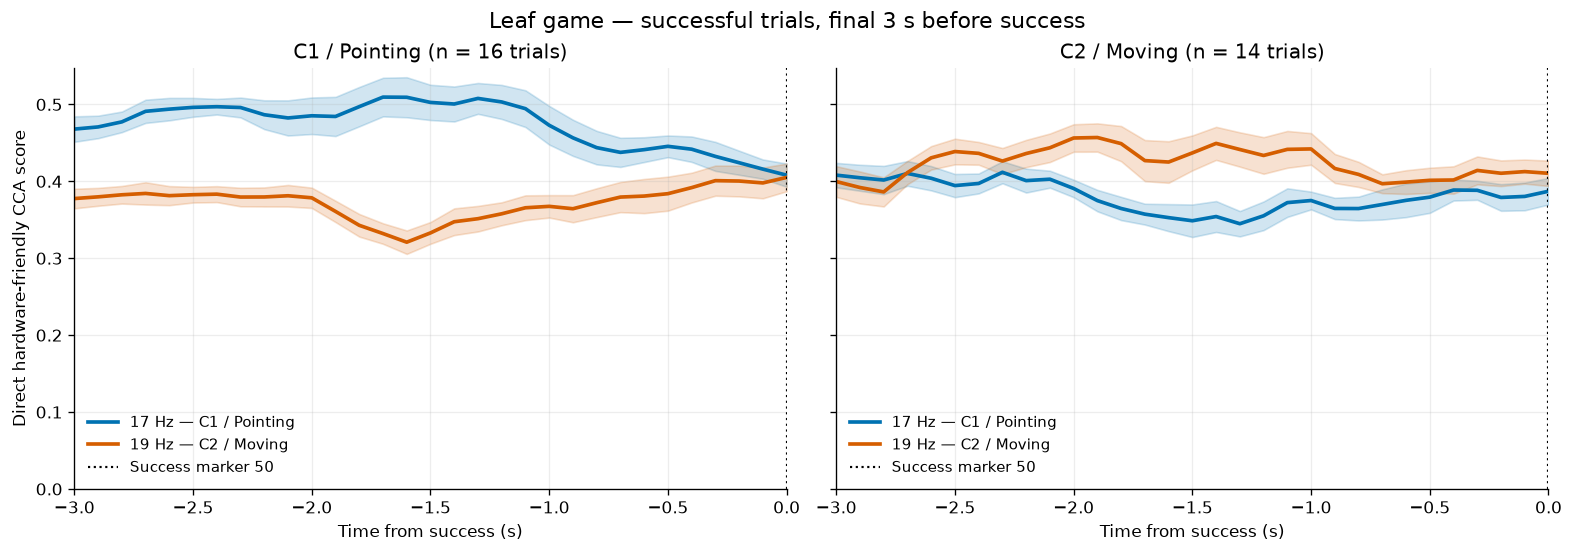

In [7]:
# All power-clean leaf trials: final 4 s, trial-end locked.
leaf_end_time = np.linspace(-END_LOCKED_SECONDS, 0,
                            int(round(END_LOCKED_SECONDS / CCA_STEP_SECONDS)) + 1)
plot_cca(leaf_trials, list(leaf_labels.values()), leaf_end_time,
         'Leaf game — all power-clean trials, final 4 s before trial end',
         ('C1 / Pointing', 'C2 / Moving'), lock='end')

# Success-marker trials only: final 3 s, locked to marker 50.
leaf_success_time = np.linspace(-SUCCESS_LOCKED_SECONDS, 0,
                                int(round(SUCCESS_LOCKED_SECONDS / CCA_STEP_SECONDS)) + 1)
plot_cca(leaf_trials, list(leaf_labels.values()), leaf_success_time,
         'Leaf game — successful trials, final 3 s before success',
         ('C1 / Pointing', 'C2 / Moving'), lock='success', success_rule='marker')